In [9]:
# Import libraries
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Import data
obs = pd.read_csv('/Users/cuvlin/Documents/MEDS/eds220/eds220-in-class/data/55_Hare_Data_2012.txt')

### Re acquaint with the data

In [10]:
obs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   object 
 1   time        264 non-null    object 
 2   grid        3380 non-null   object 
 3   trap        3368 non-null   object 
 4   l_ear       3332 non-null   object 
 5   r_ear       3211 non-null   object 
 6   sex         3028 non-null   object 
 7   age         1269 non-null   object 
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    object 
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   object 
dtypes: float64(3), int64(1), object(10)
memory usage: 369.8+ KB


In [12]:
obs['date'] = pd.to_datetime(obs['date'])
print(obs['date'].dtype)

datetime64[ns]


## Examine the hares age data

In [13]:
obs['age'].value_counts(dropna=False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

when a decsion, document it.
we will keep all hares with a  as juvenile and all hares with an A as an adult

In [15]:
# Update age valeus to juvenile and adult for observations where 'a' and 'j' are included
obs.loc[obs['age'].str.contains('j', case=False, na=False), 'age'] = 'juvenile'
obs.loc[obs['age'].str.contains('a', case=False, na=False), 'age'] = 'adult'

# Filter for condirmed obervatons of juvenile and adult hares
obs_juv_adult = obs[obs['age'].isin(['juvenile', 'adult'])]

In [21]:
# Extract year in which each obervation happened
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year

<positron-console-cell-21>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [25]:
# Count observations per year and age, then move age values into columns
obs_per_year = obs_juv_adult.groupby(['year','age']).size().unstack()
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


<Axes: title={'center': 'Juveniel and adult snowshoe hare captures per year'}, xlabel='Year', ylabel='# Captures'>

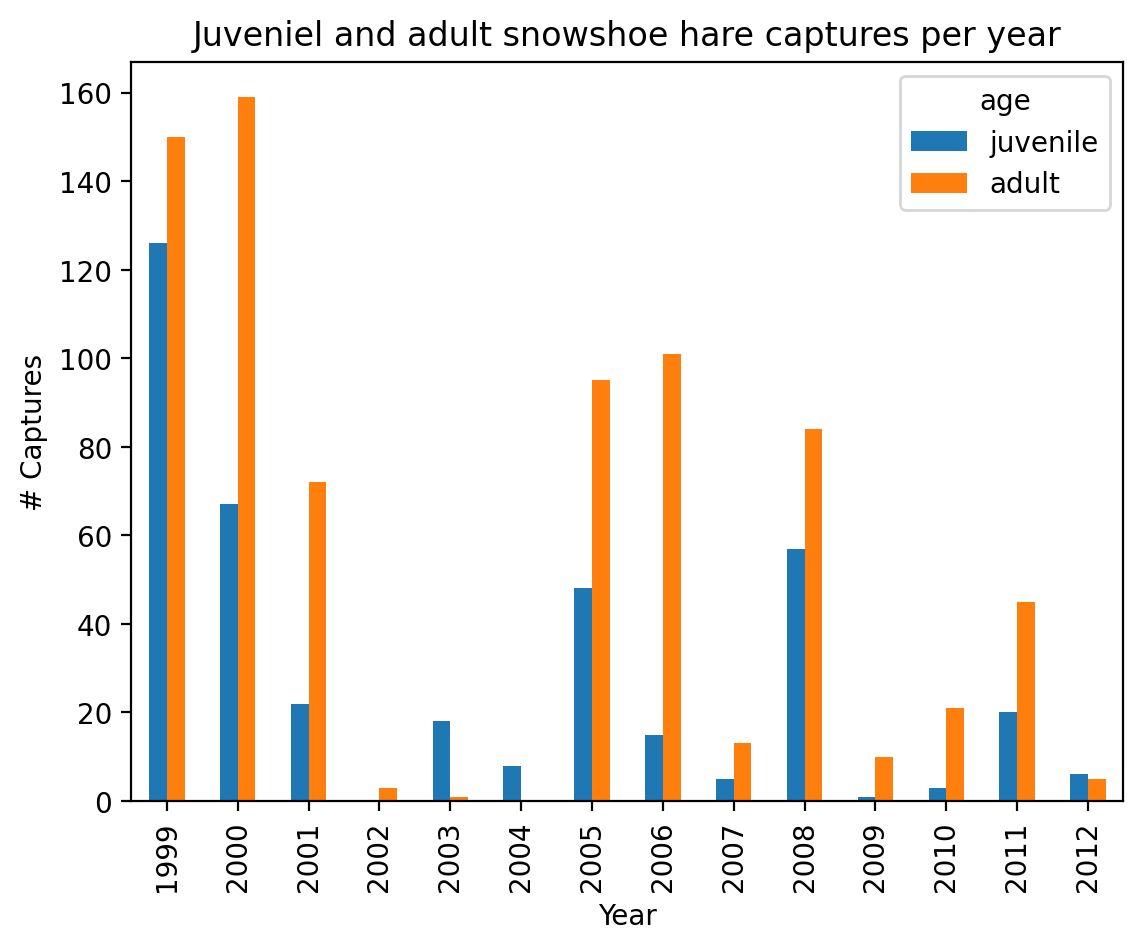

In [27]:
obs_per_year[['juvenile', 'adult']].plot(kind='bar',
                                        stacked=False,
                                        title='Juveniel and adult snowshoe hare captures per year',
                                        xlabel='Year',
                                        ylabel='# Captures')

In [ ]:
## Plotting with matplotlib

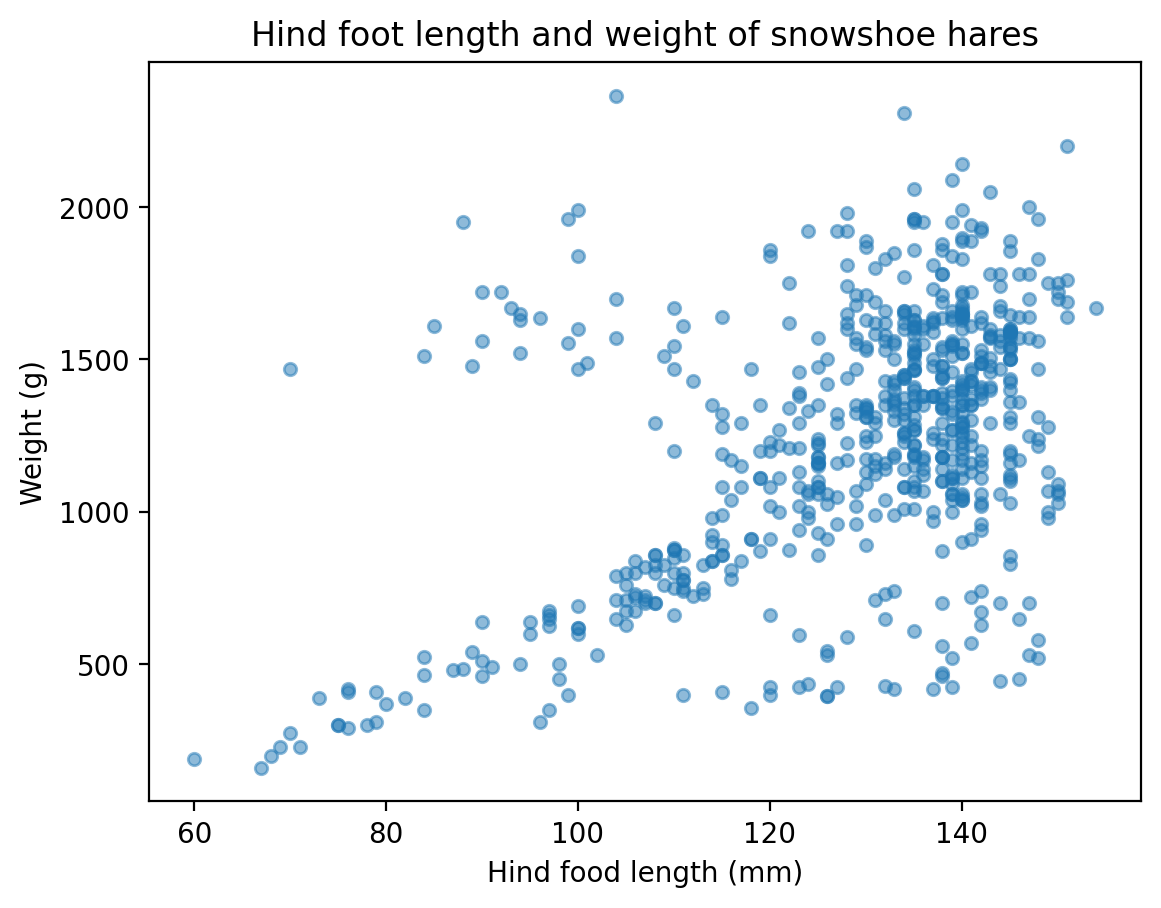

In [34]:
# Initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# Add scatterplot of hared data to out figure axes
obs_juv_adult.plot(kind='scatter', x='hindft', y='weight', ax=ax, alpha=0.5)

# Update axes
ax.set_title('Hind foot length and weight of snowshoe hares')
ax.set_xlabel("Hind food length (mm)")
ax.set_ylabel('Weight (g)')
plt.show()

## Linear regression

FOr our analysis we want to tinvestiage possible relationsh between hind foot lengh and weight for juvenile hares.


In [35]:
juveniles_weight_hindft = obs_juv_adult[obs_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])

Number of observations 265


<Axes: xlabel='hindft', ylabel='weight'>

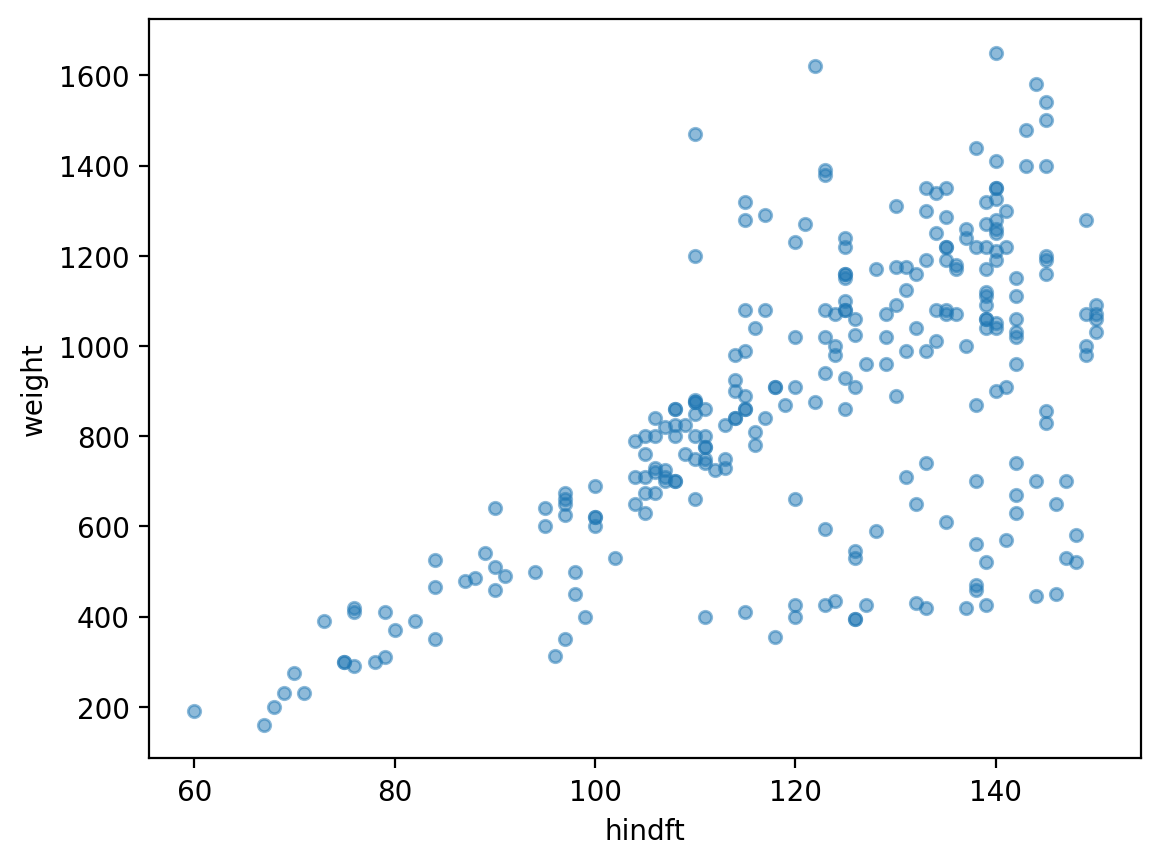

In [ ]:
print('Number of observations', len(juveniles_weight_hindft))
juveniles_weight_hindft.plot.scatter(x='hindft', y='weight', alpha=0.5)

In [39]:
# Fit model: weight explaind by hind foot length
model = smf.ols('weight ~ hindft', data=juveniles_weight_hindft).fit()
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [44]:
intercept = model.params['Intercept']
slope = model.params['hindft']

In [40]:
print('R^2', model.rsquared)

R^2 0.3871164783665738


In [42]:
# Smllest and largest hind foot lengths
x_start = juveniles_weight_hindft['hindft'].min()
x_end = juveniles_weight_hindft['hindft'].max()

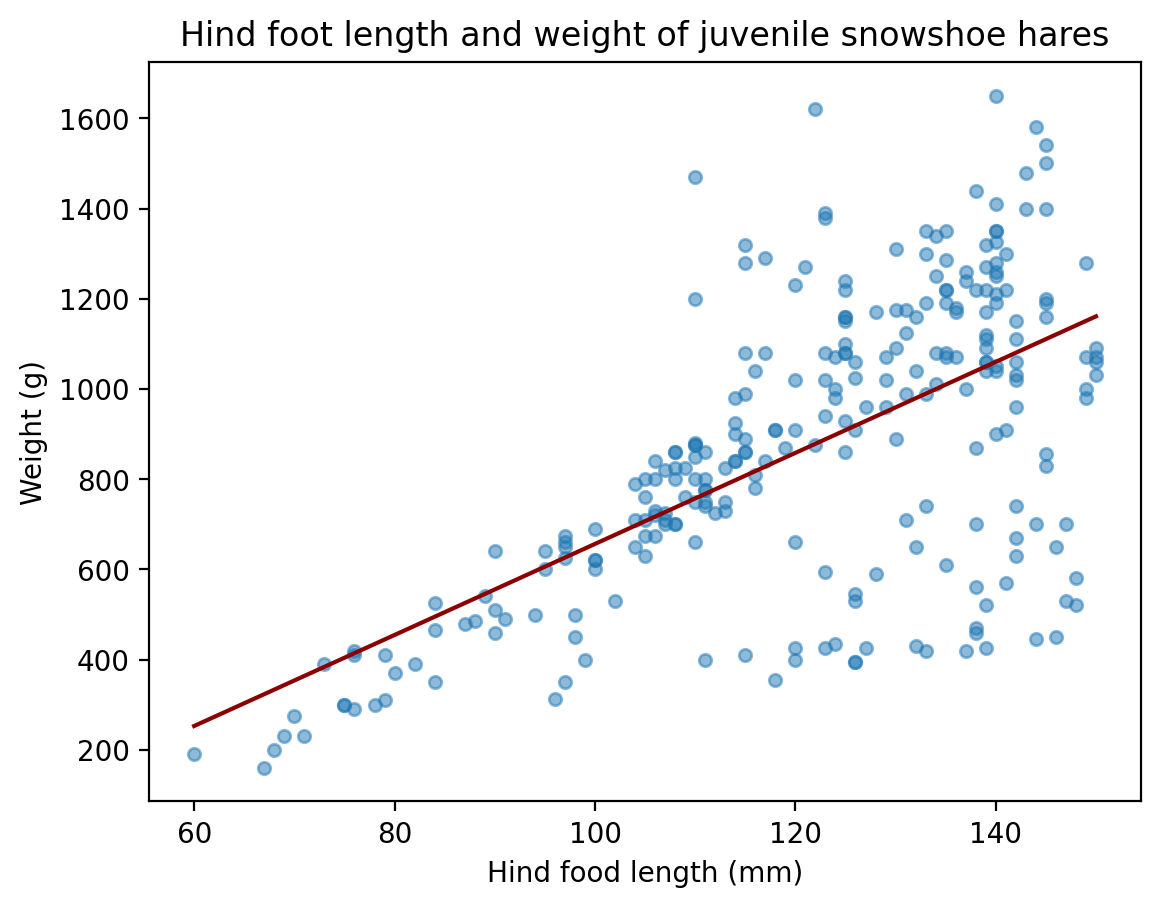

In [45]:
# Initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# Add scatterplot of hared data to out figure axes
juveniles_weight_hindft.plot(kind='scatter', x='hindft', y='weight', ax=ax, alpha=0.5)

# Add regression line to axes
ax.plot([x_start, x_end], 
[intercept +slope*x_start, intercept +slope*x_end],
color='darkred')

# Update axes
ax.set_title('Hind foot length and weight of juvenile snowshoe hares')
ax.set_xlabel("Hind food length (mm)")
ax.set_ylabel('Weight (g)')
plt.show()